# Walkthrough: `09_risk_drivers.py` (Behavioral `t-1` Features, WOE/IV & Stability PSI)

### Simple Summary
**This script builds 8 strictly lagged (`t-1`) behavioral features for every December snapshot (such as worst arrears in the past 6/12 months and indexed LTV), measures each feature's predictive power using Laplace-smoothed Weight of Evidence and Information Value (IV), and checks population stability (PSI) across eras.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`module2_sample.duckdb`) strictly **read-only in memory** and calls `compute_woe_iv_table()` live without writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Lagged t-1 Features</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">6m/12m DPD, LTV &amp; mod</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. +0.5 Smoothed WOE</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Exact dist sum == 1.0</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. IV &amp; Spearman</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Rank predictive strength</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. IV Ranking Chart</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Behavioral vs. origination</text>
</svg>
</div>

---
### 1. Computing Laplace-Smoothed WOE/IV Live (`compute_woe_iv_table`)
If a feature band has zero defaults in a benign era, naive log-odds divide by zero. Adding `+0.5` Laplace smoothing guarantees finite Weight of Evidence (`WOE`) and forces `sum(dist_bad) == 1.0` and `sum(dist_good) == 1.0`. Below we pass band counts from `risk_drivers_mart` through `compute_woe_iv_table()` live and verify exact normalization.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only IV/WOE verification
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then insert scripts/ for importing 09_risk_drivers
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 09_risk_drivers and restore Jupyter inline plotting (module2_common sets Agg)
# Switch matplotlib backend back to inline and attach module2_sample.duckdb strictly READ_ONLY
rd_mod = importlib.import_module("09_risk_drivers")
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Recompute WOE/IV tables live from saved counts and verify exact 1.0 distribution sums
# Query counts from m2.risk_drivers_mart, run rd_mod.compute_woe_iv_table(), and inspect FICO bands
cnts = con.execute("SELECT era, feature_name, band, loans, bads FROM m2.risk_drivers_mart").fetchdf()
rd_live, iv_live = rd_mod.compute_woe_iv_table(cnts)
max_sum_err = rd_live.groupby(["era", "feature_name"])[["dist_bad", "dist_good"]].sum().sub(1.0).abs().max().max()
print(f"WOE distribution normalization error: {max_sum_err:.2e} (PASS)")
rd_live[(rd_live["feature_name"] == "credit_score") & (rd_live["era"] == "2007-2010 crisis")][["band", "loans", "bads", "default_rate", "woe", "iv_contrib"]].round(4)

WOE distribution normalization error: 2.22e-16 (PASS)


,band,loans,bads,default_rate,woe,iv_contrib
123,740-779,3037,30,0.0099,0.8987,0.1569
124,<620,419,34,0.0811,-1.2789,0.1251
125,missing,56,2,0.0357,-0.6105,0.0027
126,620-659,833,49,0.0588,-0.9294,0.1094
127,780+,2418,8,0.0033,1.9551,0.3960
128,700-739,2136,48,0.0225,0.0702,0.0010
129,660-699,1565,80,0.0511,-0.7772,0.1328


In the 2007–2010 crisis, FICO `<620` defaults at far higher rates than `780+`, producing a steep monotonic WOE curve. Next, we rank all 15 origination and behavioral drivers by average Information Value across eras.

---
### 2. Ranking Predictive Power (IV) Across Origination & Behavioral Drivers
Credit risk rules of thumb treat `IV < 0.02` as weak, `0.02–0.10` as mild, `0.10–0.30` as strong, and `> 0.30` as very strong. Plotting mean IV across all 15 features shows immediately why behavioral `t-1` arrears dominate origination scores.

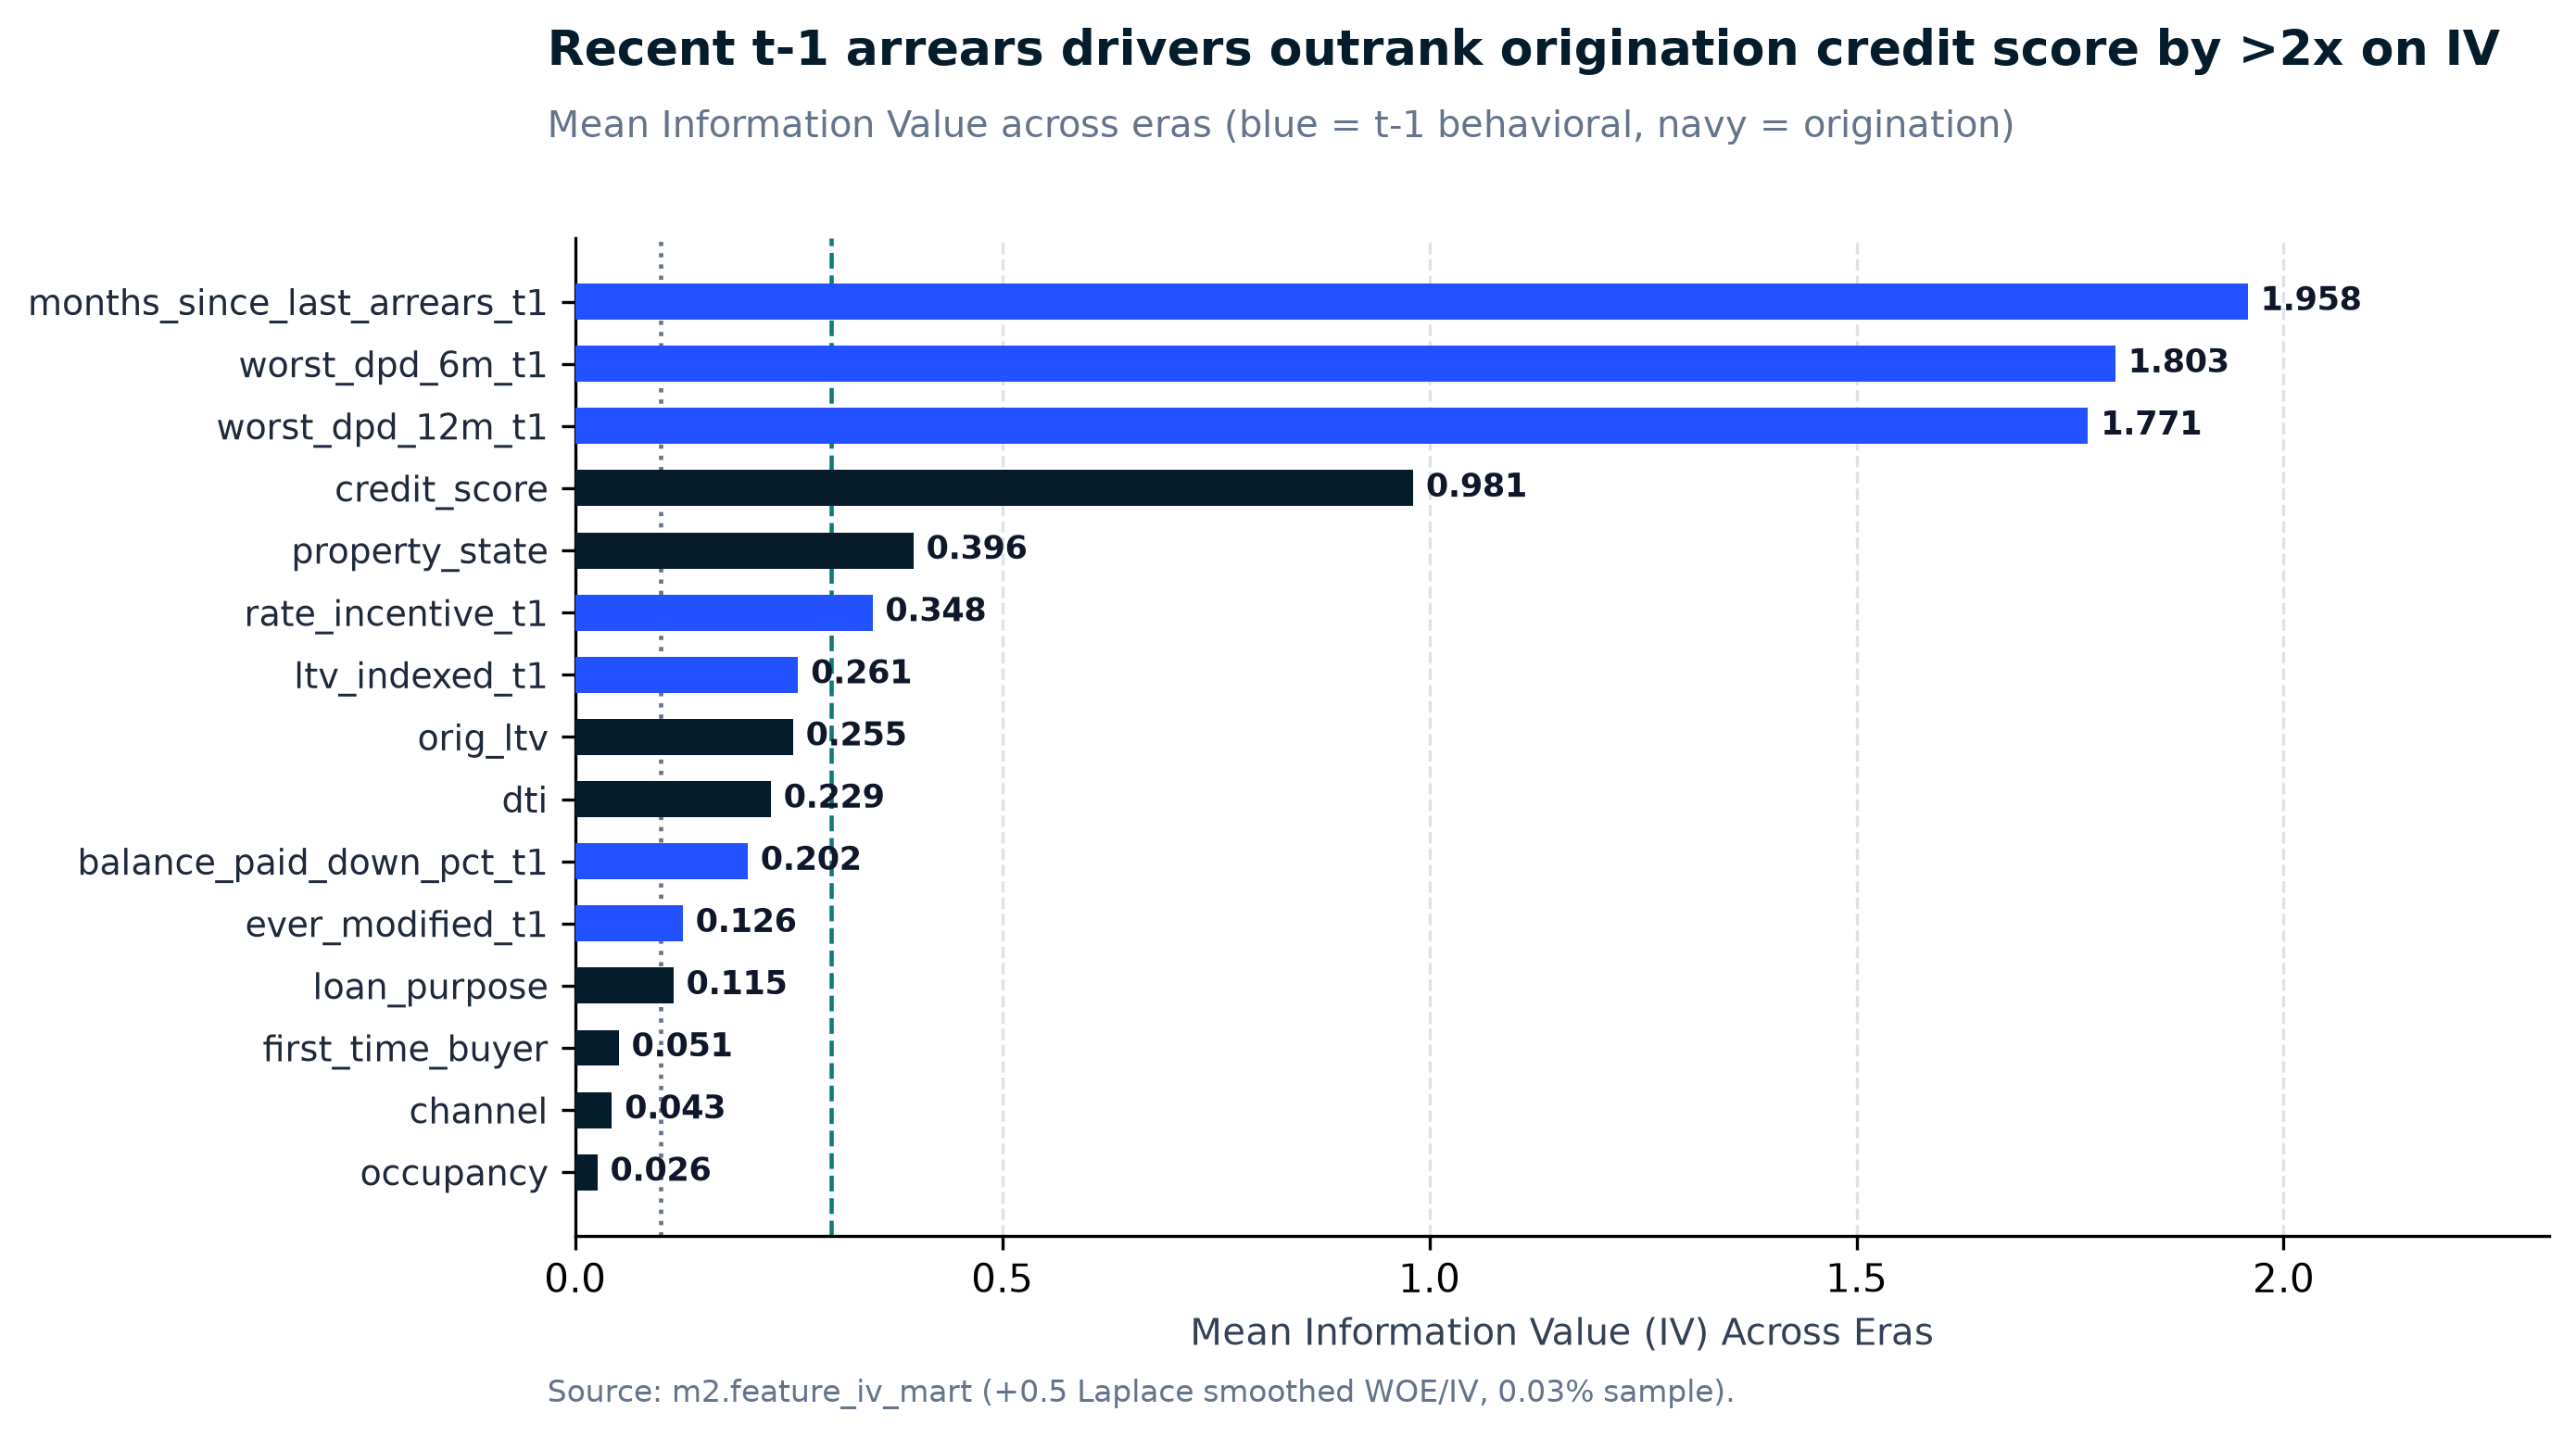

In [2]:
# Rank all 15 origination and behavioral features by mean IV across eras
# Group m2.feature_iv_mart by feature_name, tag behavioral vs. origination, and plot at 300 dpi
iv_rank = con.execute("""
    SELECT feature_name, round(avg(information_value), 3) AS mean_iv,
           round(avg(psi_vs_all), 3) AS mean_psi
    FROM m2.feature_iv_mart
    GROUP BY feature_name
    ORDER BY mean_iv ASC
""").fetchdf()
beh_set = set(rd_mod.BEH_FEATURES.keys())
bar_colors = ["#2251FF" if f in beh_set else "#051C2C" for f in iv_rank["feature_name"]]

fig, ax = plt.subplots(figsize=(10.0, 5.2), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.barh(range(len(iv_rank)), iv_rank["mean_iv"], color=bar_colors, height=0.58, zorder=3)
for i, val in enumerate(iv_rank["mean_iv"]):
    ax.text(val + 0.015, i, f"{val:.3f}", va="center", fontsize=8.5, fontweight="bold", color="#0F172A")
ax.axvline(0.10, color="#64748B", linestyle=":", linewidth=1.1, zorder=2)
ax.axvline(0.30, color="#0E7C7B", linestyle="--", linewidth=1.1, zorder=2)
ax.set_yticks(range(len(iv_rank)))
ax.set_yticklabels(iv_rank["feature_name"], fontsize=9, color="#1E293B")
ax.set_xlim(0, iv_rank["mean_iv"].max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Mean Information Value (IV) Across Eras", fontsize=9.5, color="#334155")
fig.text(0.24, 0.94, "Recent t-1 arrears drivers outrank origination credit score by >2x on IV", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.24, 0.89, "Mean Information Value across eras (blue = t-1 behavioral, navy = origination)", fontsize=9.5, color="#64748B")
fig.text(0.24, 0.015, "Source: m2.feature_iv_mart (+0.5 Laplace smoothed WOE/IV, 0.03% sample).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.25, right=0.96, top=0.82, bottom=0.13)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

Lagged behavioral delinquency (`worst_dpd_12m_t1`, `months_since_last_arrears_t1`, `worst_dpd_6m_t1`) sits far above the `0.30` threshold, while `credit_score` and `ltv_indexed_t1` anchor origination and collateral risk. Next, `10_segmentation.py` tests whether splitting the portfolio into separate sub-models is statistically justified.